Saurabh Bansal
2026B01010297

In [5]:
import pandas as pd
import numpy as np
clean=pd.read_csv("bank_data_clean.csv")
print(clean.head())

  Customer_ID    City Account_Type Employment_Type Preferred_Channel  Age  \
0       C1075    Pune      Savings         Retired       Net_Banking   74   
1       C1130   Delhi      Current   Self_Employed        Mobile_App   53   
2       C1070  Indore      Current        Salaried       Net_Banking   46   
3       C1107   Delhi      Savings   Self_Employed        Mobile_App   62   
4       C1228    Pune       Salary        Salaried          ATM_Only   25   

   Monthly_Income  Tenure_Years  Monthly_Transactions Last_Activity_Date  \
0           64000           7.9                  20.0         2025-06-08   
1           60500           9.0                  28.0         2025-09-12   
2           28000          10.2                  30.0         2025-11-30   
3           32500          22.6                  18.0         2025-11-24   
4           25000           3.2                  32.0         2026-07-16   

   Avg_Monthly_Balance  Income_per_Transaction Customer_Segment Tenure_Group  
0

In [6]:
%pip install matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


## Q1- What does the Avg_Monthly_Balance look like overall ?

count       250.0
mean      72671.0
std       33580.0
min        2000.0
25%       48375.0
50%       71180.0
75%       96192.0
max      155740.0
Name: Avg_Monthly_Balance, dtype: float64
Skewness: 0.19


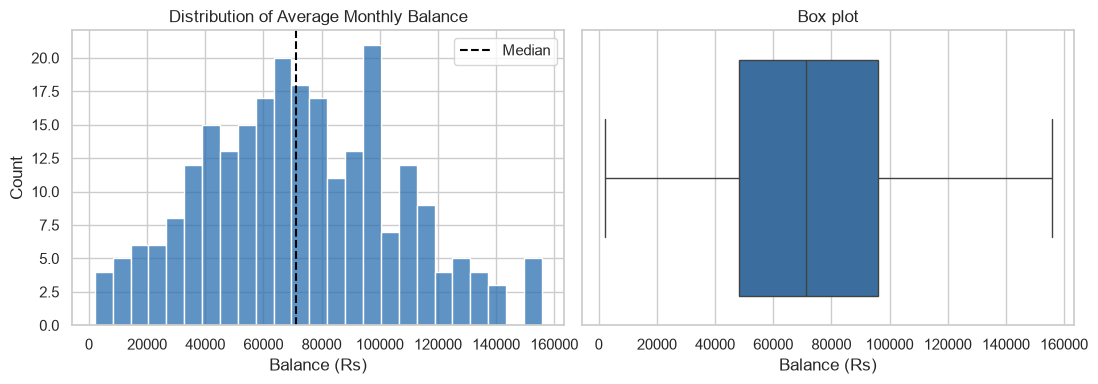

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
BLUE = "#2a6fb0"
sns.set_theme(style="whitegrid")
out = "Avg_Monthly_Balance"
print(clean[out].describe().round(0))
print("Skewness:", round(clean[out].skew(), 2))
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(clean[out], bins=25, color=BLUE, ax=ax[0])
ax[0].axvline(clean[out].median(), color="black", ls="--", label="Median")
ax[0].set_title("Distribution of Average Monthly Balance")
ax[0].set_xlabel("Balance (Rs)")
ax[0].legend()
sns.boxplot(x=clean[out], color=BLUE, ax=ax[1])
ax[1].set_title("Box plot")
ax[1].set_xlabel("Balance (Rs)")
plt.tight_layout()
plt.savefig("q1_overall.png", dpi=150)
plt.show()

## Q2-Do Monthly_Income and Tenure_Years affect Avg_Monthly_Balance?

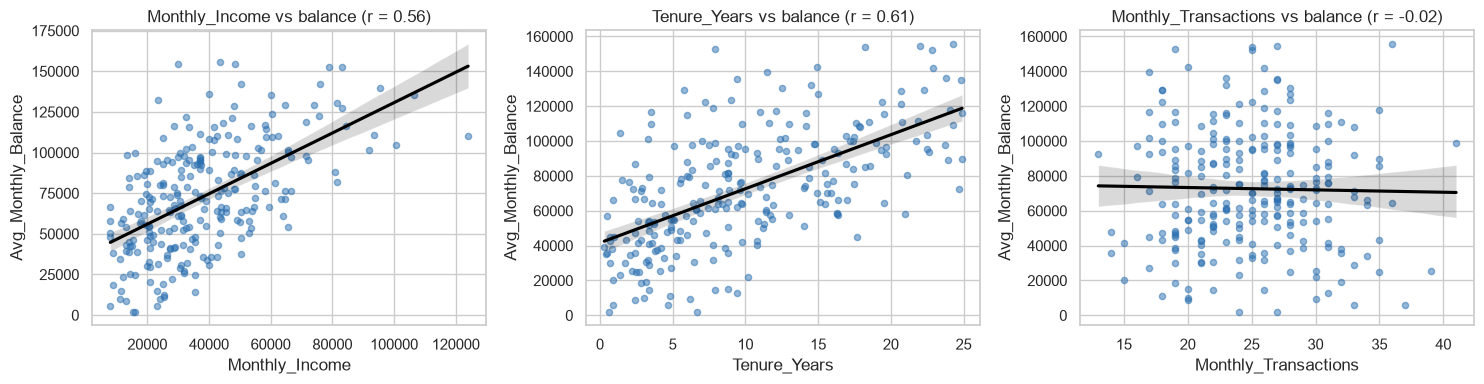

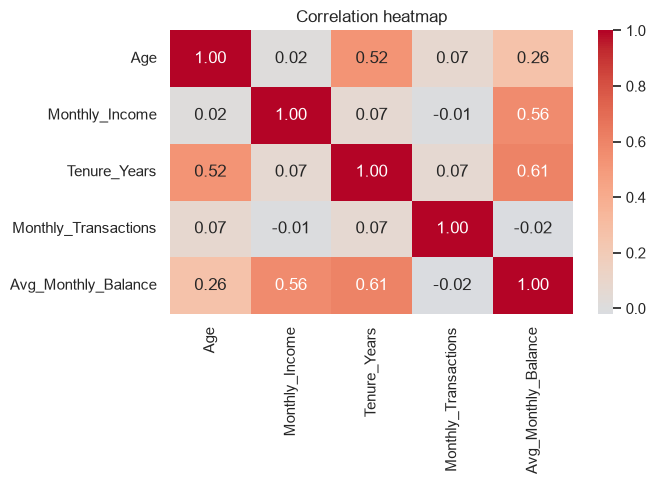

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, col in zip(ax, ["Monthly_Income", "Tenure_Years", "Monthly_Transactions"]):
    sns.regplot(data=clean, x=col, y=out, ax=a, color=BLUE,
                scatter_kws={"alpha": 0.5, "s": 20}, line_kws={"color": "black"})
    a.set_title(f"{col} vs balance (r = {clean[col].corr(clean[out]):.2f})")
plt.tight_layout()
plt.savefig("q2_scatter.png", dpi=150)
plt.show()

num = ["Age", "Monthly_Income", "Tenure_Years", "Monthly_Transactions", out]
plt.figure(figsize=(7, 5))
sns.heatmap(clean[num].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap")
plt.tight_layout()
plt.savefig("q2_heatmap.png", dpi=150)
plt.show()

## Q2-Does Avg_Monthly_Balance differ by City, Account_Type,Employment_Type or Preferred_Channel? 

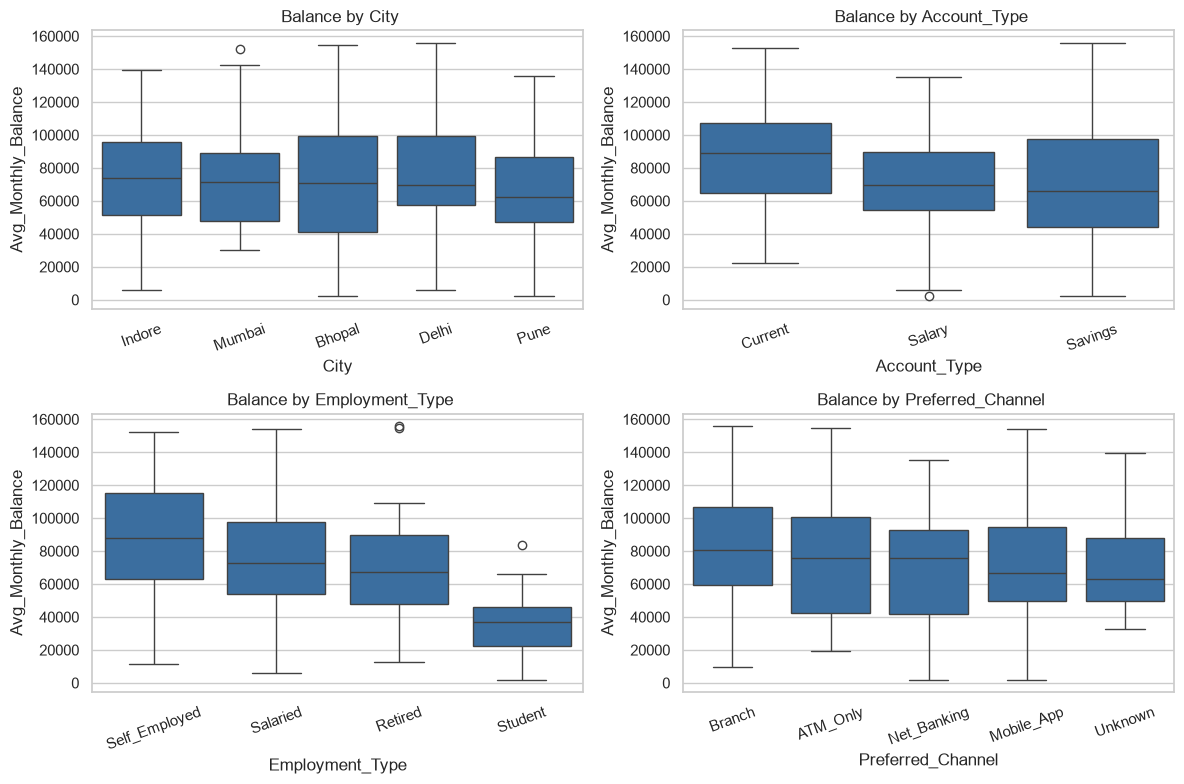

        count     mean   median
City                           
Bhopal     62  70137.0  70625.0
Delhi      41  79104.0  69410.0
Indore     74  74096.0  74120.0
Mumbai     43  72988.0  71680.0
Pune       30  65152.0  62435.0 

              count     mean   median
Account_Type                         
Current          34  84972.0  88975.0
Salary           74  70442.0  69725.0
Savings         142  70888.0  65910.0 

                 count     mean   median
Employment_Type                         
Retired             36  69741.0  67275.0
Salaried           126  75079.0  72860.0
Self_Employed       60  86872.0  88230.0
Student             28  35174.0  36885.0 

                   count     mean   median
Preferred_Channel                         
ATM_Only              18  74704.0  75710.0
Branch                46  82078.0  80905.0
Mobile_App           122  71262.0  66710.0
Net_Banking           60  67579.0  75640.0
Unknown                4  74712.0  63225.0 



In [17]:
cats = ["City", "Account_Type", "Employment_Type", "Preferred_Channel"]
fig, ax = plt.subplots(2, 2, figsize=(12, 8))
for a, c in zip(ax.flat, cats):
    order = clean.groupby(c)[out].median().sort_values(ascending=False).index
    sns.boxplot(data=clean, x=c, y=out, order=order, color=BLUE, ax=a)
    a.set_title(f" Balance by {c}")
    a.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.savefig("q3_categories.png", dpi=150)
plt.show()
for c in cats:
    print(clean.groupby(c)[out].agg(["count", "mean", "median"]).round(0), "\n")

## Q4-Which records need attention?

Low Balance customers: 19 (7.6%)


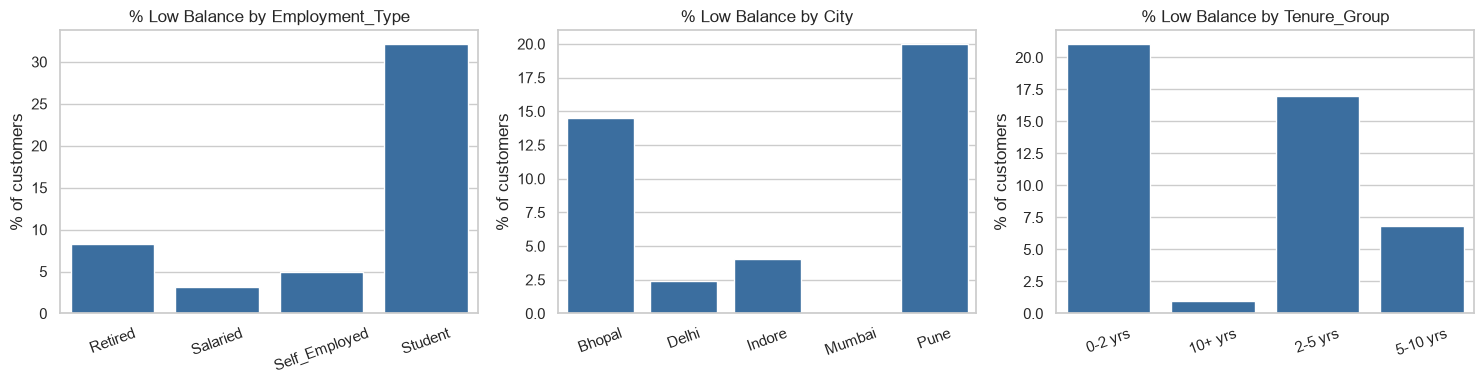

    Customer_ID    City Account_Type Employment_Type Preferred_Channel  Age  \
206       C1116  Bhopal      Savings         Student       Net_Banking   20   
219       C1166    Pune       Salary         Student        Mobile_App   24   
211       C1083  Indore       Salary        Salaried        Mobile_App   47   
208       C1195   Delhi      Savings         Student       Net_Banking   18   
8         C1081  Bhopal      Savings         Student       Net_Banking   22   
101       C1151    Pune      Savings        Salaried            Branch   36   
27        C1206  Bhopal      Savings         Student       Net_Banking   24   
105       C1032  Indore       Salary   Self_Employed        Mobile_App   42   
193       C1125  Bhopal      Savings         Retired        Mobile_App   76   
113       C1141  Bhopal      Savings   Self_Employed       Net_Banking   52   

     Monthly_Income  Tenure_Years  Monthly_Transactions Last_Activity_Date  \
206           16000           0.6                  2

In [19]:
low = clean[clean["Customer_Segment"] == "Low Balance"]
print("Low Balance customers:", len(low), f"({len(low)/len(clean):.1%})")
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, c in zip(ax, ["Employment_Type", "City", "Tenure_Group"]):
    share = (clean.assign(low=clean["Customer_Segment"] == "Low Balance")
               .groupby(c, observed=True)["low"].mean() * 100)
    sns.barplot(x=share.index, y=share.values, color=BLUE, ax=a)
    a.set_title(f"% Low Balance by {c}")
    a.set_ylabel("% of customers")
    a.set_xlabel("")
    a.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.savefig("q4_low_balance.png", dpi=150)
plt.show()
print(low.sort_values(out).head(10))

## Key Insights

In [20]:
out = "Avg_Monthly_Balance"
low = clean[clean["Customer_Segment"] == "Low Balance"]

r_inc = clean["Monthly_Income"].corr(clean[out])
r_ten = clean["Tenure_Years"].corr(clean[out])
r_txn = clean["Monthly_Transactions"].corr(clean[out])
emp = clean.groupby("Employment_Type")[out].mean()
acc = clean.groupby("Account_Type")[out].mean()
stu_low = (low["Employment_Type"] == "Student").sum()

print(f"1. Average balance: Rs {clean[out].mean():,.0f}; median Rs {clean[out].median():,.0f}.")
print(f"2. Income vs balance correlation = {r_inc:.2f}; tenure vs balance = {r_ten:.2f}; transactions vs balance = {r_txn:.2f}.")
print(f"3. Highest-balance group: {emp.idxmax()} (Rs {emp.max():,.0f}); lowest: {emp.idxmin()} (Rs {emp.min():,.0f}).")
print(f"4. Current accounts average Rs {acc['Current']:,.0f} vs Rs {acc['Savings']:,.0f} for Savings.")
print(f"5. {len(low)} customers are Low Balance; {stu_low} of them are students. Their average tenure is {low['Tenure_Years'].mean():.1f} years.")

1. Average balance: Rs 72,671; median Rs 71,180.
2. Income vs balance correlation = 0.56; tenure vs balance = 0.61; transactions vs balance = -0.02.
3. Highest-balance group: Self_Employed (Rs 86,872); lowest: Student (Rs 35,174).
4. Current accounts average Rs 84,972 vs Rs 70,888 for Savings.
5. 19 customers are Low Balance; 9 of them are students. Their average tenure is 4.3 years.


##  Recommendations

- **Focus on students and new customers.** Students keep the lowest balances and make up about half of all Low Balance customers. Offer them a student savings plan with small automatic monthly deposits.
- **Reward long-standing customers and attract higher earners.** Tenure and income are the two factors most linked to higher balances. Run loyalty benefits to keep long-term customers, and offer premium products to higher-income customers.
- **Promote Current accounts and target self-employed customers.** They hold the highest balances, so they are the best group for investment and business-banking offers.
- **Do not use transaction count as a sign of a good customer.** It has almost no link to balance, so judge customers by balance, income and tenure instead.
- **Watch the Low Balance list monthly.** Contact customers below Rs 25,000 early, especially those in their first 5 years with the bank.
